# TP11 — Datastorytelling : état du marché

**But du notebook :** préparer progressivement le récit, les graphiques et le mini-deck du TP11. Complète les cellules Markdown vides après chaque étape. Ce notebook est un support de travail, pas le livrable de présentation final.

**Branche proposée :** `Klement/feat/tp11-datastorytelling`

**Périmètre à garder en tête :** l’EDA de référence porte sur un échantillon Open Food Facts de 8 400 produits après nettoyage minimal. Présente donc les observations comme des résultats sur cet échantillon, pas comme des estimations représentatives de tout le marché.

**Livrables TP11 :** mini-deck de 8 slides maximum et fonctions de tracé réutilisables dans `src/viz.py`.

## Mode de travail guidé

Tu écris le code fonctionnel. L’assistant inspecte le dépôt, prépare les tests d’acceptation et la documentation, explique les interfaces et t’accompagne dans les choix sans écrire l’implémentation métier à ta place. Avance une étape à la fois : demande des indices quand tu en veux, puis fais relire ton raisonnement ou ton code avant de passer à la suite.

L’étape 1 est déjà rédigée dans ce notebook. L’étape à reprendre est l’étape 2. Les trois fonctions de tracé déjà présentes dans les cellules de code sont des prototypes à examiner et valider, pas des interfaces imposées d’avance.


## Fil conducteur

Pour chaque résultat, avance dans cet ordre : **message → chiffre vérifié → graphique → interprétation → limite → conséquence pour NutriScope**. Vise un deck de 7 slides, couverture comprise, puis ajuste si le récit l’exige.

À la fin de chaque étape, arrête-toi pour expliquer tes choix et montrer le résultat. Nous vérifierons ensemble les chiffres, le raisonnement ou le code avant d’ouvrir l’étape suivante. Les indices sont repliés dans la section de l’étape 3 : ne les consulte que si tu les demandes.


## Étape 1 — Définir le récit et choisir les messages

**Objectif** — Sélectionner les 6 à 8 résultats de l’EDA qui aident la direction à comprendre l’échantillon et les enjeux NutriScope.

**À faire**

- [X] Définir le public et la conclusion générale à retenir.
- [X] Relire la synthèse TP10 et vérifier chaque chiffre dans le notebook de référence.
- [X] Choisir 6 à 8 messages maximum parmi les résultats sur les sucres, les grades, les rayons inconnus, la complétude, la qualité des données, les corrélations et les valeurs extrêmes.
- [X] Pour chaque message, noter le chiffre et son unité, la population concernée, la comparaison utile, une limite et la conséquence pour NutriScope.
- [X] Écarter les résultats trop techniques ou redondants.

**Résultat attendu** — Liste de messages vérifiés, prêts à devenir les titres des visuels.

**Commit associé** — `définit les messages du datastorytelling TP11`

**Notes / rédaction**


### Public et angle du récit

- **Public du deck :** la direction de NutriScope.
- **Utilisateur auquel le récit se réfère :** un parent pressé qui veut comparer rapidement des produits pendant ses courses.
- **Angle :** montrer ce que l’échantillon révèle sur les différences entre rayons, puis signaler les limites de classement et de complétude des données.
- **Périmètre :** les résultats décrivent l’échantillon Open Food Facts après nettoyage minimal. Ils ne représentent pas nécessairement l’ensemble du marché alimentaire.

### Messages retenus

#### 1. Les snacks sucrés se distinguent par leur teneur en sucres

- **Chiffre et unité :** médiane de **38 g de sucres pour 100 g**, avec un premier quartile de 24 g et un troisième quartile de 53 g. La médiane du rayon suivant, les boissons, est de **6,1 g/100 g**.
- **Population concernée :** produits avec un rayon connu et une valeur de sucres renseignée : **1 185 snacks sucrés** et **452 boissons**.
- **Comparaison utile :** la médiane des snacks sucrés est environ six fois celle des boissons.
- **Limite :** ces médianes décrivent les produits de l’échantillon et non chaque produit de ces rayons ni l’ensemble du marché.
- **Conséquence pour NutriScope :** faciliter la comparaison des produits au sein de leur rayon et attirer l’attention sur les catégories particulièrement sucrées.

#### 2. Les grades Nutri-Score varient fortement selon les rayons

- **Chiffre et unité :** parmi les produits notés, **66,1 %** des snacks sucrés sont E et **50,3 %** des fruits et légumes sont A.
- **Population concernée :** **5 149 produits** de rayon connu ayant un grade exploitable de A à E. Les snacks sucrés comptent **1 098 produits notés** et les fruits et légumes **344**.
- **Comparaison utile :** les snacks sucrés et les fruits et légumes présentent des répartitions de grades très différentes.
- **Limite :** les produits sans grade exploitable, notamment `unknown` et `not-applicable`, sont exclus. Le Nutri-Score ne décrit pas à lui seul tous les aspects nutritionnels d’un produit.
- **Conséquence pour NutriScope :** présenter le grade avec le contexte du rayon et éviter d’en faire une évaluation complète du produit.

#### 3. Un produit sur cinq n’a pas de rayon exploitable

- **Chiffre et unité :** **1 726 produits sur 8 400**, soit **20,5 %**, n’ont pas de rayon connu.
- **Population concernée :** l’ensemble des **8 400 produits** de l’échantillon après nettoyage minimal. Les 1 726 produits comprennent **1 700 produits classés `unknown`** et **26 sans valeur de rayon**.
- **Comparaison utile :** seuls **6 674 produits** peuvent être utilisés dans les comparaisons par rayon.
- **Limite :** les données utilisées pour cette EDA ne permettent pas encore de rattacher ces produits sans rayon aux catégories du Parquet.
- **Conséquence pour NutriScope :** améliorer le classement des produits avant d’étendre les comparaisons à l’ensemble du catalogue.

#### 4. La complétude des fiches varie selon les rayons

- **Chiffre et unité :** **79,5 %** des fiches sont complètes pour les sept nutriments clés sur l’ensemble des rayons connus. Dix rayons se situent entre **71 % et 92 %** ; les boissons alcoolisées sont à **14 %**.
- **Population concernée :** les **6 674 produits** dont le rayon est connu. Pour chaque produit, on vérifie si les sept nutriments clés sont renseignés. Les produits `unknown` ne sont pas inclus dans le résultat global par rayon.
- **Comparaison utile :** la complétude n’est pas uniforme selon les rayons. Les fiches des boissons alcoolisées sont nettement moins complètes que celles de la plupart des autres rayons. Les aliments pour bébés montrent par ailleurs qu’une fiche complète ne garantit pas qu’un Nutri-Score soit disponible.
- **Limite :** une fiche complète signifie que les sept valeurs sont présentes, pas qu’elles sont exactes. Les pourcentages par rayon reposent aussi sur des effectifs différents.
- **Conséquence pour NutriScope :** afficher les informations manquantes et tenir compte de la complétude avant de comparer des produits ou des rayons.

#### 5. Certains produits présentent un écart important avec le calcul d’énergie

- **Chiffre et unité :** **119 produits sur 6 731**, soit environ **1,8 %**, ont un écart supérieur à **150 kcal/100 g** entre l’énergie déclarée et l’estimation 4/4/9. Parmi ces produits, 52 sont sous l’estimation et 67 au-dessus.
- **Population concernée :** les **6 731 produits** pour lesquels l’énergie déclarée, les glucides, les protéines et les lipides sont tous renseignés.
- **Comparaison utile :** la grande majorité des produits ayant les données nécessaires présente un écart inférieur ou égal au seuil de 150 kcal/100 g.
- **Limite :** le calcul 4/4/9 est une estimation simplifiée, pas une valeur de référence parfaite. Un écart important signale un produit à examiner, mais ne prouve pas à lui seul une erreur.
- **Conséquence pour NutriScope :** conserver des contrôles de cohérence et vérifier les fiches signalées avant de corriger ou d’écarter leurs valeurs.

#### 6. Les valeurs extrêmes ne sont pas toutes des erreurs

- **Chiffre et unité :** **1 371 produits sur 6 674**, soit **20,5 %**, ont au moins une valeur signalée comme extrême par rapport à leur rayon. Parmi les 15 cas les plus extrêmes relus manuellement, 9 sont jugés plausibles, 5 résiduels et 1 plausible mais associé à un rayon incorrect.
- **Population concernée :** les **6 674 produits de rayon connu**. Le repérage porte sur les valeurs renseignées des nutriments analysés ; un produit est compté s’il possède au moins une valeur signalée.
- **Comparaison utile :** le repérage statistique trouve des valeurs éloignées du profil de leur rayon, mais l’examen manuel montre que plusieurs correspondent à des produits plausibles.
- **Limite :** la relecture ne porte que sur les 15 cas les plus extrêmes. Elle ne permet pas d’estimer la proportion d’erreurs parmi tous les produits signalés.
- **Conséquence pour NutriScope :** utiliser ces seuils pour prioriser la vérification des données, pas pour supprimer automatiquement les produits concernés.

#### 7. La qualité des données conditionne la fiabilité de NutriScope

- **Chiffre et unité :**
  - **20,5 %** des produits n’ont pas de rayon exploitable : 1 726 sur 8 400.
  - **79,5 %** des produits à rayon connu ont les sept nutriments clés renseignés : 5 307 sur 6 674.
  - **119 produits sur 6 731**, soit environ **1,8 %**, présentent un écart énergétique absolu supérieur à 150 kcal/100 g.
- **Population concernée :** l’échantillon global de **8 400 produits** après nettoyage minimal, avec un dénominateur distinct pour chaque indicateur.
- **Comparaison utile :** les problèmes de classement, les informations nutritionnelles manquantes et les écarts énergétiques représentent trois limites différentes de la fiabilité des données.
- **Limite :** ces indicateurs ne partagent pas le même dénominateur. La présence des nutriments ne garantit pas leur exactitude, et un écart énergétique important ne prouve pas une erreur.
- **Conséquence pour NutriScope :** associer la comparaison nutritionnelle à une information claire sur la qualité des fiches, et contrôler les valeurs signalées sans les corriger ou les supprimer automatiquement.

### Résultats écartés du récit principal

- **Moyennes et médianes des sucres et du sel :** l’asymétrie des distributions justifie de privilégier médianes et quartiles, mais ce point est redondant avec le message sur les sucres. À garder comme explication de méthode dans la présentation.
- **Corrélations entre nutriments et Nutri-Score :** elles sont surtout utiles pour préparer le modèle du TP14 et sont plus techniques que les autres messages. Elles ne seront pas dans le récit principal.
- **V de Cramér de 0,34 :** il quantifie le lien entre rayon et grade, mais apporte peu de plus au graphique qui montre déjà la répartition des grades par rayon.
- **Hypothèses bio/NOVA et autres tests exploratoires :** elles nécessitent davantage d’explications et ne sont pas prioritaires pour ce deck court.
- **Complétude par marque :** les graphies de marques ne sont pas regroupées et les effectifs sont partiels. Ce résultat pourra être repris après normalisation.
- **Point sur les « effectifs » et le sel :** écarté pour le moment, car sa formulation ne permet pas d’identifier clairement le résultat visé.

### Fil conducteur

> L’échantillon révèle des différences marquées entre rayons, mais une part importante des produits est mal catégorisée ou incomplètement documentée. NutriScope devra donc associer la comparaison nutritionnelle à une information claire sur la qualité et les limites des données.

## Étape 2 — Choisir et concevoir les graphiques

**Objectif** — Associer un graphique lisible à chacun des messages déjà retenus, avec une seule idée par visuel.

### Progression

1. Relis les six messages de l’étape 1 et les trois prototypes existants : `tracer_medianes_sucres`, `tracer_grades_mis_en_avant` et `tracer_couverture_rayons`.
2. Complète une spécification par message. Décide du type de graphique, du titre, des axes et unités, de la population et du dénominateur, des effectifs à afficher, de la source et de la limite à rappeler.
3. Propose une charte graphique commune et indique les visuels qui restent à concevoir.
4. Présente tes spécifications pour relecture. Ne commence pas l’extraction des fonctions vers `src/viz.py` avant validation.

| Message retenu | Type de graphique | Titre-conclusion | Population / dénominateur | Axes et unités | Effectif / source | Limite affichée |
|---|---|---|---|---|---|---|
| **1. Les snacks sucrés se distinguent par leur teneur en sucres** | Diagramme en barres horizontales comparant les médianes, avec indication du premier et du troisième quartile pour les snacks sucrés | « Les snacks sucrés contiennent environ six fois plus de sucres que les boissons » | Produits avec un rayon connu et une valeur de sucres renseignée ; dénominateur propre à chaque rayon | X : sucres (g/100 g) ; Y : catégorie de produits | Snacks sucrés : 1 185 produits, médiane 38 g/100 g, Q1 = 24 et Q3 = 53. Boissons : 452 produits, médiane 6,1 g/100 g. Source : Open Food Facts, échantillon NutriScope de 8 400 produits | Les médianes décrivent les produits de l’échantillon, pas nécessairement l’ensemble du marché français. |
| **2. Les grades Nutri-Score varient fortement selon les rayons** | Barres horizontales empilées à 100 %, réparties par classe de Nutri-Score | « Les snacks sucrés sont majoritairement classés E, tandis que les fruits et légumes sont souvent classés A » | Produits de rayon connu disposant d’un grade exploitable de A à E ; dénominateur propre à chaque catégorie | X : part des produits notés (%) ; Y : catégorie ; segments : classes A à E | 5 149 produits notés au total. Snacks sucrés : 1 098 produits, dont 66,1 % classés E. Fruits et légumes : 344 produits, dont 50,3 % classés A. Source : Open Food Facts | Les produits sans grade exploitable, notamment `unknown` et `not-applicable`, sont exclus. Le Nutri-Score ne décrit pas à lui seul tous les aspects nutritionnels d’un produit. |
| **3. Un produit sur cinq n’a pas de rayon exploitable** | Barre horizontale empilée à 100 %, distinguant les produits avec rayon exploitable et ceux sans rayon exploitable | « 20,5 % des produits n’ont pas de rayon exploitable » | Ensemble des 8 400 produits après nettoyage minimal ; dénominateur = 8 400 | X : part des produits (%) ; Y : échantillon ; segments : rayon exploitable / rayon absent ou inexploitable | 6 674 produits avec rayon exploitable ; 1 726 sans rayon exploitable, soit 20,5 %, dont 1 700 `unknown` et 26 sans valeur de rayon. Source : Open Food Facts, traitement NutriScope | L’absence de rayon exploitable ne signifie pas nécessairement que le produit ne possède aucune catégorie dans la source. |
| **4. La complétude des fiches varie selon les rayons** | Diagramme en barres horizontales comparant le taux de complétude des sept nutriments clés par rayon | « La complétude nutritionnelle varie fortement selon les rayons » | Produits dont le rayon est connu ; dénominateur global = 6 674, avec des effectifs propres à chaque rayon | X : fiches complètes pour les sept nutriments clés (%) ; Y : rayon | Globalement, 5 307 produits sur 6 674 sont complets, soit 79,5 %. Dix rayons se situent entre 71 % et 92 % ; boissons alcoolisées : 14 %. Source : Open Food Facts, indicateur de complétude NutriScope | La présence des sept nutriments ne garantit ni leur exactitude ni la cohérence des valeurs. Les pourcentages par rayon reposent sur des effectifs différents. |
| **5. Certains produits présentent un écart important avec le calcul d’énergie** | Barres horizontales divergentes montrant les 10 à 15 écarts absolus les plus importants, avec valeurs signées | « Un écart énergétique important mérite une vérification, mais ne prouve pas une erreur » | Produits disposant de l’énergie déclarée, des glucides, des protéines et des lipides ; dénominateur = 6 731 | X : énergie calculée moins énergie déclarée (kcal/100 g) ; Y : produit identifié par nom, éventuellement complété par son code | 119 produits sur 6 731, soit environ 1,8 %, présentent un écart absolu supérieur à 150 kcal/100 g ; 52 ont une énergie déclarée supérieure à l’estimation et 67 une estimation supérieure à la valeur déclarée. Source : Open Food Facts et estimation NutriScope par facteurs 4/4/9 | Le calcul 4/4/9 est une estimation simplifiée. Un écart important signale un produit à examiner, mais ne prouve pas une erreur. |
| **6. Les valeurs extrêmes ne sont pas toutes des erreurs** | Diagramme de synthèse du repérage des valeurs extrêmes, complété par un examen des 15 cas les plus extrêmes | « Une valeur extrême doit être vérifiée avant d’être considérée comme erronée » | Produits de rayon connu ; dénominateur = 6 674 pour le repérage global. Relecture manuelle limitée à 15 cas | X : nombre de produits ou part des produits (%) pour le repérage global ; pour la relecture : nombre de cas par conclusion | 1 371 produits sur 6 674, soit 20,5 %, ont au moins une valeur signalée comme extrême. Parmi les 15 cas relus : 9 plausibles, 5 résiduels et 1 plausible mais associé à un rayon incorrect. Source : Open Food Facts, détection statistique et relecture NutriScope | La relecture porte uniquement sur les 15 cas les plus extrêmes. Elle ne permet pas d’estimer la proportion d’erreurs parmi tous les produits signalés. |
| **7. La qualité des données conditionne la fiabilité de NutriScope** | Visuel de synthèse composé de trois indicateurs distincts : couverture des rayons, complétude nutritionnelle et écarts énergétiques | « Avant de comparer les produits, il faut tenir compte de la qualité des données disponibles » | Périmètre global de 8 400 produits après nettoyage minimal, avec un dénominateur propre à chaque indicateur | Pas d’axes communs : trois indicateurs séparés, chacun avec sa valeur, son unité et son dénominateur | **Couverture :** 1 726 / 8 400 sans rayon exploitable, soit 20,5 %. **Complétude :** 5 307 / 6 674 fiches complètes pour les sept nutriments, soit 79,5 %. **Écarts énergétiques :** 119 / 6 731 produits évaluables, soit 1,8 %, avec un écart absolu supérieur à 150 kcal/100 g. Source : Open Food Facts, calculs NutriScope | Les indicateurs portent sur des populations différentes. La présence des nutriments ne garantit pas leur exactitude, et un écart énergétique important ne prouve pas une erreur. |

### Critères d’acceptation

- Chaque visuel soutient un message de l’étape 1 et n’essaie pas d’en raconter plusieurs à la fois.
- Les unités, la population et le dénominateur des pourcentages sont explicites.
- Les titres annoncent le constat sans généraliser au-delà de l’échantillon de 8 400 produits.
- Les limites nécessaires et la source Open Food Facts sont prévues.
- Les six messages tiennent dans le récit sans graphiques redondants ; la couverture reste comprise dans les 8 slides maximum.

**Point de contrôle** — Explique pourquoi le type de graphique convient à chaque message et comment le lecteur peut retrouver la population représentée. Fais valider le tableau et la charte avant de passer à l’étape 3.

**Résultat attendu** — Spécifications validées pour les visuels du mini-deck.

**Commit associé** — `définit les spécifications graphiques du TP11`


In [10]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Trouver la racine du dépôt, que le notebook soit lancé depuis
# le dossier du projet ou depuis notebooks/
RACINE = next(
    (
        chemin
        for chemin in [Path.cwd(), *Path.cwd().parents]
        if (chemin / "src" / "eda_lib.py").exists()
    ),
    None,
)

if RACINE is None:
    raise RuntimeError("Impossible de trouver la racine du dépôt NutriScope.")

if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

from src import eda_lib, viz
from importlib import reload
from src.cleaning import lire_brut

# Couleurs utilisées par le graphique
BLEU = "#2a78d6"
GRIS = "#c3c2b7"
ENCRE = "#0b0b0b"

# Charger et préparer les données de l'EDA de référence
brut = lire_brut(RACINE / "data" / "echantillon_france.csv")
perimetre = eda_lib.nettoyage_minimal(brut)
par_rayon = eda_lib.rayons_connus(perimetre)

# Calculer les statistiques nécessaires au graphique
profil_sucres = eda_lib.profil_par_rayon(
    par_rayon,
    ["sugars_100g"],
).loc["sugars_100g"]

# 4. La complétude nutritionnelle reste imparfaite 
completude_rayons = eda_lib.completude_par_groupe(
    perimetre,
    eda_lib.RAYON,
    eda_lib.NUTRIMENTS_CLES,
    min_n=20,
)

# 5. Certains produits présentent un écart important entre deux estimations énergétiques
comparables = perimetre.copy()

comparables["energie_calculee"] = eda_lib.energie_calculee(comparables)

comparables["ecart_energie"] = (
    comparables["energie_calculee"] - comparables["energy-kcal_100g"]
)

comparables = comparables.dropna(
    subset=["energie_calculee", "energy-kcal_100g"]
)

# 6. Les valeurs extrêmes ne sont pas toutes des erreurs
extremes = eda_lib.extremes_restants(
    par_rayon,
    eda_lib.NUTRIMENTS_CLES,
)

reload(viz)

<module 'src.viz' from 'c:\\Users\\Administrateur\\Documents\\NutriScope\\src\\viz.py'>

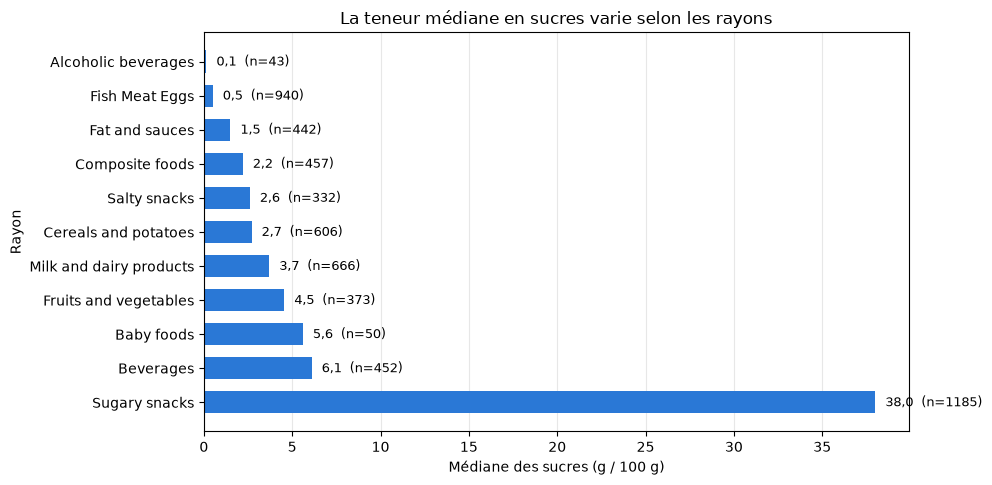

In [11]:
# 1. Les snacks sucrés sont plus concentrés en sucres que les boissons
from src import viz

fig, ax = viz.tracer_medianes_sucres(profil_sucres)
plt.show()

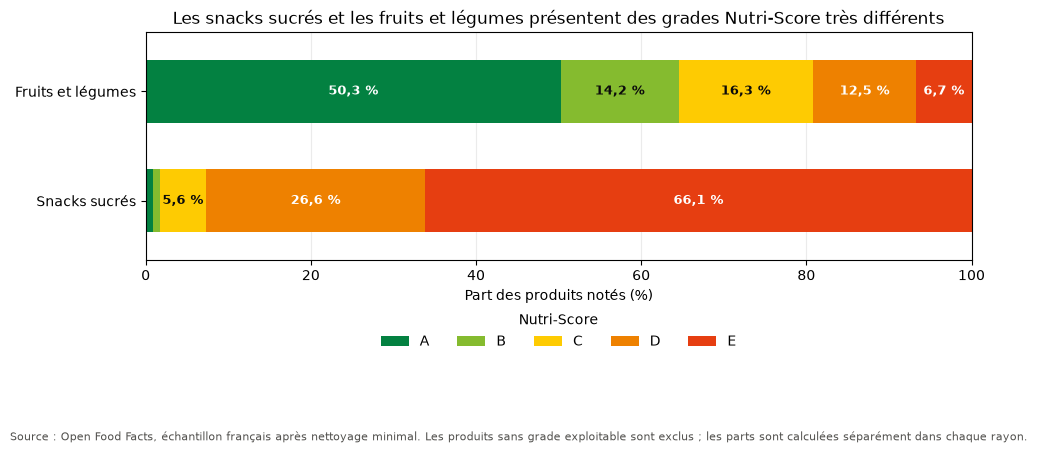

In [12]:
# 2. Les snacks sucrés présentent fréquemment un Nutri-Score E, contrairement aux fruits et légumes
fig, ax = viz.tracer_grades_mis_en_avant(par_rayon)
plt.show()

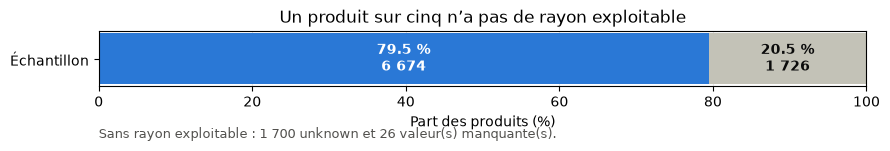

In [13]:
# 3. Un produit sur cinq ne possède pas de rayon exploitable
fig, ax = viz.tracer_couverture_rayons(perimetre)
plt.show()

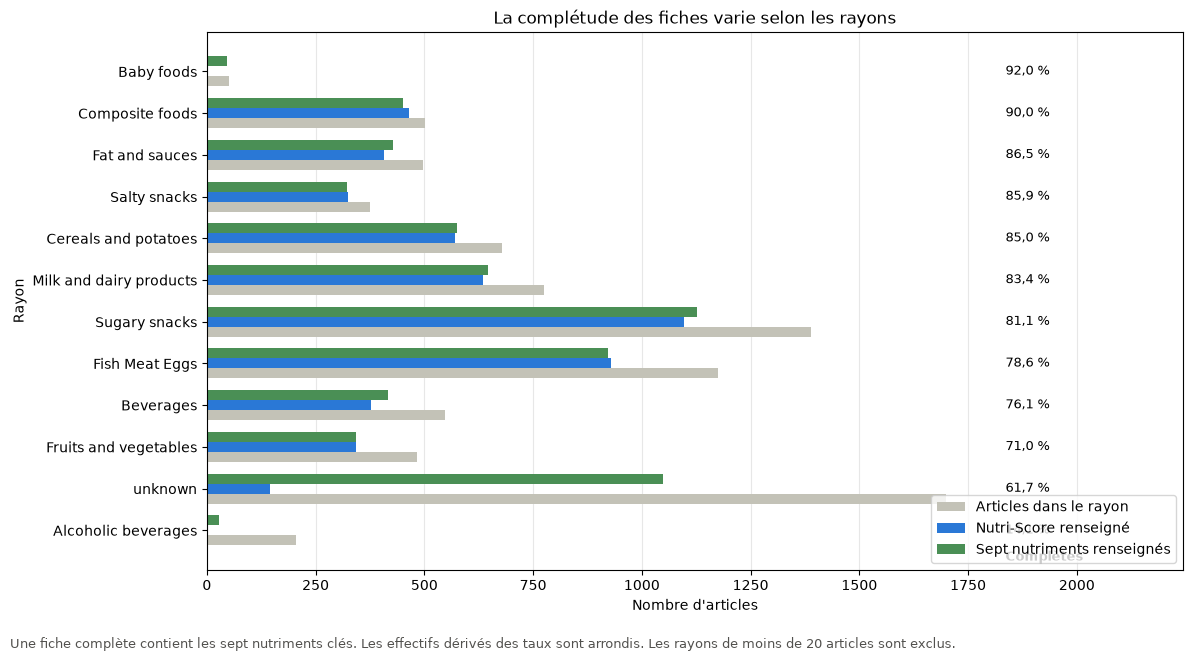

In [14]:
# 4. La complétude nutritionnelle reste imparfaite
fig, ax = viz.tracer_completude_rayons(completude_rayons)
plt.show()

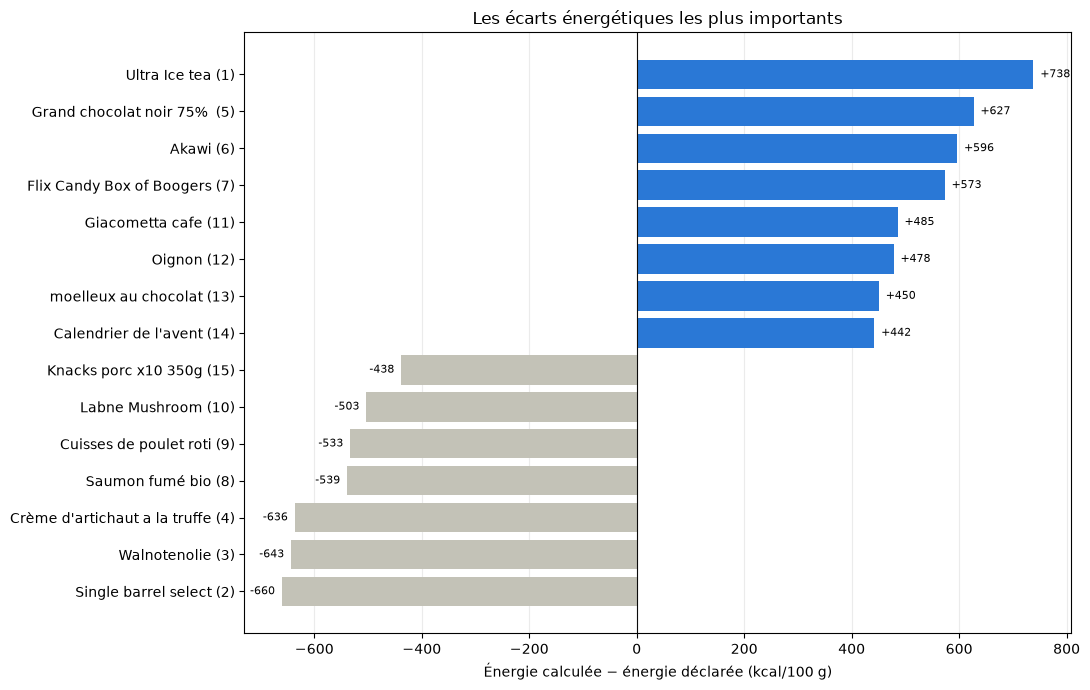

In [15]:
# 5. Certains produits présentent un écart important entre deux estimations énergétiques
fig, ax = viz.tracer_ecarts_energetiques(comparables)
plt.show()

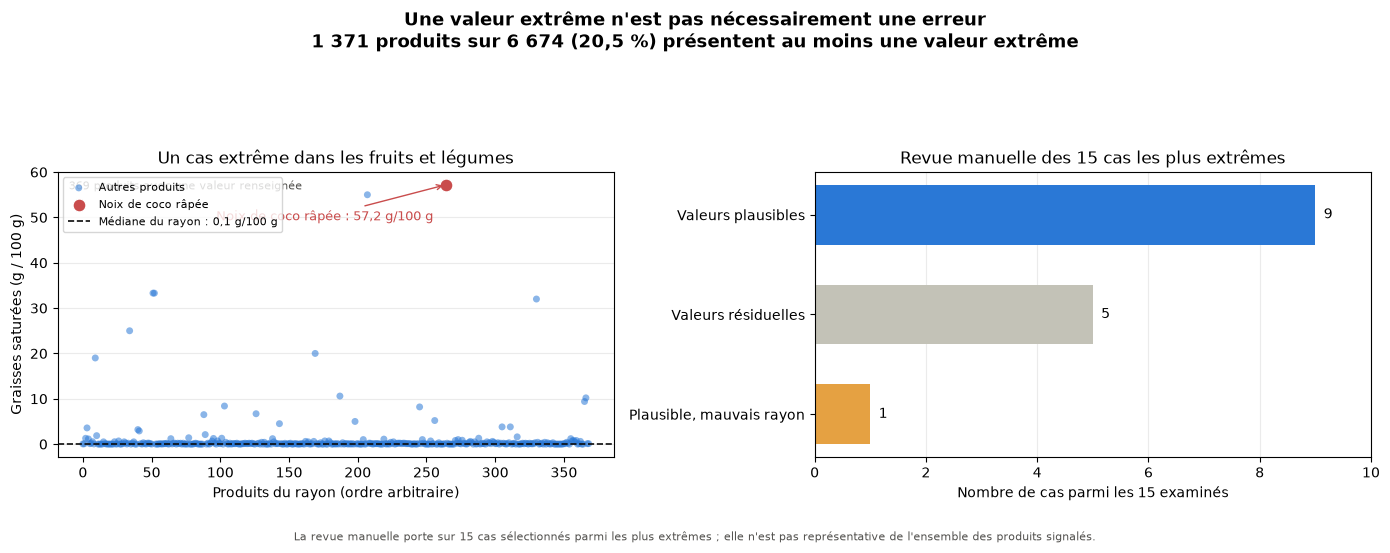

In [16]:
# 6. Les valeurs extrêmes ne sont pas toutes des erreurs
fig, axes = viz.tracer_bilan_valeurs_extremes(
    extremes=extremes,
    total_rayons_connus=len(par_rayon),
    par_rayon=par_rayon,
)
plt.show()

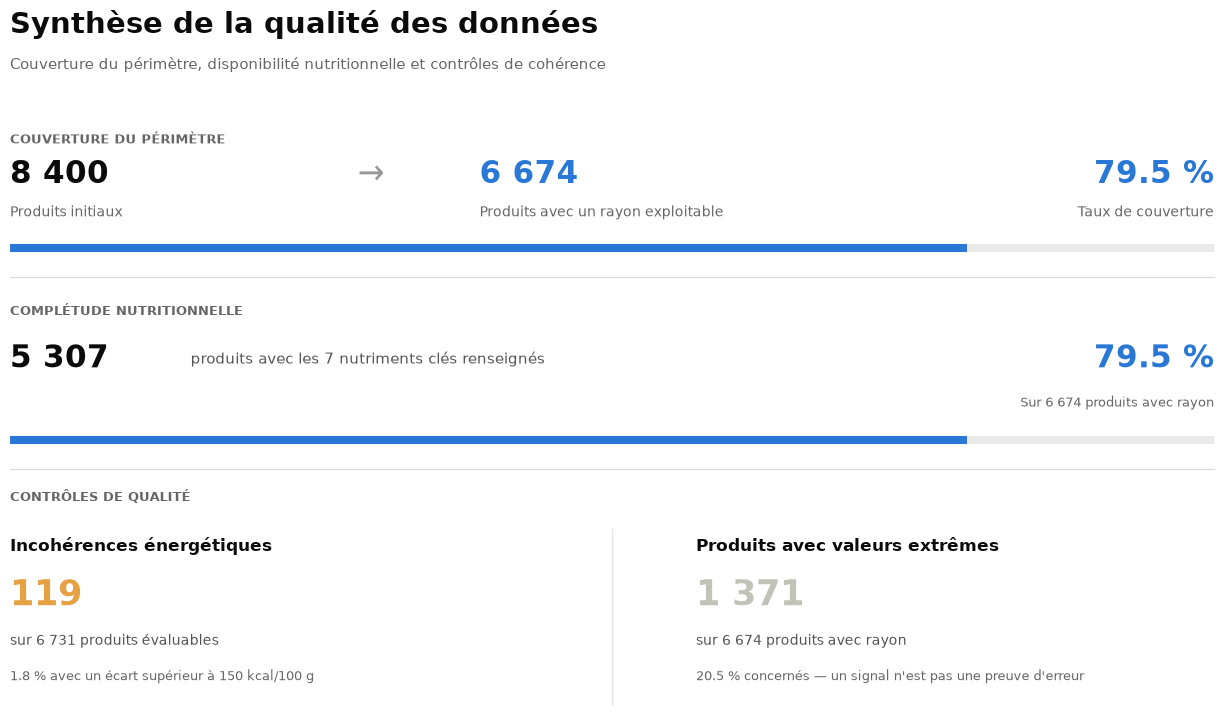

In [17]:
# 7. La qualité des données conditionne la fiabilité de NutriScope


fig, axes = viz.tracer_synthese_qualite(
    perimetre=perimetre,
    comparables=comparables,
    extremes=extremes,
)

plt.show()

## Étape 3 — Créer les fonctions réutilisables dans `src/viz.py`

**Objectif** — Extraire et faire évoluer les prototypes validés dans un module réutilisable, en séparant calculs et rendu.

### Interfaces de départ

Les prototypes existants donnent trois interfaces candidates à examiner avec les spécifications de l’étape 2 :

- `tracer_medianes_sucres(profil_sucres)` : affiche les médianes et effectifs déjà calculés par l’EDA.
- `tracer_grades_mis_en_avant(df)` : compare les parts de grades choisies dans deux rayons.
- `tracer_couverture_rayons(produits)` : montre la part des produits avec et sans rayon exploitable.

Garde les noms et paramètres s’ils restent cohérents après la relecture. Pour les autres graphiques, définis les interfaces après avoir choisi leurs visuels. La décision à vérifier ensemble est la frontière entre les calculs de `src/eda_lib.py` et le rendu de `src/viz.py` : évite de recopier les calculs déjà testés.

### Progression

1. Inspecte `src/eda_lib.py`, `tests/test_eda_lib.py` et les prototypes du notebook. Vérifie aussi les dépendances et conventions déjà présentes.
2. Confirme les signatures et les comportements d’entrée/sortie avec l’assistant avant de coder.
3. Déplace ou refactorise une fonction à la fois dans `src/viz.py`. Une fonction renvoie sa figure et ses axes pour permettre à l’appelant de l’afficher ou de l’exporter ; elle ne lance pas elle-même `plt.show()` et ne sauvegarde pas le fichier du deck.
4. Après chaque fonction, lance les tests d’acceptation, explique les résultats et fais relire avant d’enchaîner.

### Critères d’acceptation

- Les fonctions retenues se trouvent dans `src/viz.py` et utilisent des entrées explicites.
- Elles rendent les graphiques décrits dans les spécifications validées et renvoient les objets figure/axes.
- Les calculs déjà couverts par `src/eda_lib.py` ne sont pas dupliqués dans le module de visualisation.
- Les données incomplètes ou les rayons requis absents ont un comportement explicite et testé.
- `tests/test_viz.py` vérifie les valeurs représentées, les libellés et les erreurs de contrat sans comparer des captures d’écran au pixel près.

### Lancer les tests

Depuis la racine du dépôt, avec l’environnement Python du projet activé :

```powershell
python -m pytest -q -p no:cacheprovider --basetemp=.pytest-tmp tests/test_viz.py
```

Les tests d’acceptation sont préparés, mais ils ne peuvent pas passer avant la création de `src/viz.py`. Ne les modifie pas pour masquer cette absence.

<details>
<summary>Indices progressifs — à ouvrir uniquement si tu les demandes</summary>

1. Pour choisir l’entrée d’une fonction de tracé, demande-toi si elle a réellement besoin des produits bruts ou si l’EDA peut lui fournir un résumé déjà calculé.
2. Un test de graphique peut vérifier les valeurs présentes dans les objets `Axes`, le titre et les unités ; il n’est pas nécessaire de comparer l’image produite pixel par pixel.

</details>

**Questions de vérification** — Quelles transformations appartiennent à `eda_lib` et lesquelles relèvent uniquement de `viz` ? Pourquoi renvoyer `(fig, ax)` ? Comment un test détecte-t-il une erreur de dénominateur sans tester la mise en page pixel par pixel ?

**Point de contrôle** — Après chaque fonction, montre le diff et les tests réellement exécutés. Nous validons ensemble avant la fonction suivante.

**Résultat attendu** — Fonctions réutilisables, testées et alignées sur les visuels validés.

**Commit associé** — `ajoute les fonctions de visualisation réutilisables du TP11`


### Réponses aux questions de vérification

**1. Quelles transformations appartiennent à `eda_lib` et lesquelles relèvent uniquement de `viz` ?**

`src/eda_lib.py` prend en charge les traitements analytiques : calcul des indicateurs, agrégation des données, définition des populations étudiées et application des règles métier. Ces calculs doivent rester centralisés et réutilisables, sans être dupliqués dans le module de visualisation.

`src/viz.py` prend en charge la représentation graphique des résultats : choix du type de graphique, positionnement des barres, couleurs, titres, axes, unités et légendes. Des transformations légères nécessaires au rendu peuvent y être effectuées, mais les indicateurs métier déjà calculés par `eda_lib` ne doivent pas y être recalculés.

**2. Pourquoi renvoyer `(fig, ax)` ?**

`fig` (`Figure`) représente la figure complète, tandis que `ax` (`Axes`) représente la zone contenant le graphique et ses éléments.

Renvoyer ces objets permet à l'appelant de contrôler le rendu : afficher la figure, modifier les axes, ajouter des annotations, composer plusieurs graphiques ou exporter le résultat. Cela rend les fonctions réutilisables et facilite les tests automatisés. La fonction n'impose ainsi ni affichage immédiat ni sauvegarde particulière.

**3. Comment un test détecte-t-il une erreur de dénominateur sans tester la mise en page pixel par pixel ?**

Le test vérifie les valeurs numériques réellement représentées dans les objets Matplotlib, en les comparant à des résultats attendus calculés à partir d'un petit jeu de données connu.

Par exemple, si 30 produits sur 50 possèdent un Nutri-Score, la proportion attendue est de 60 %. Un test peut vérifier que la barre représente bien 60 % et non une proportion calculée avec un dénominateur incorrect, comme le nombre total de produits d'un autre rayon.

Cette approche teste la justesse des données représentées indépendamment du rendu visuel : elle est plus robuste qu'une comparaison de captures d'écran, sensible aux variations de police, de résolution ou de mise en page.

## Étape 4 — Assembler le mini-deck

**Objectif** — Construire une présentation cohérente de 8 slides maximum, adaptée à une restitution courte.

**À faire**

- [ ] Slide 1 : couverture, source et périmètre de l’échantillon.
- [ ] Slides suivantes : une conclusion principale par slide, avec son graphique et une interprétation courte.
- [ ] Inclure les limites nécessaires pour ne pas généraliser les résultats à tout le marché.
- [ ] Terminer par les implications pour NutriScope et les prochaines étapes du projet.
- [ ] Vérifier le fil narratif, la cohérence graphique et le nombre maximal de slides.

**Résultat attendu** — Mini-deck « État du marché » exporté dans un format présentable.

**Critères d’acceptation** — 8 slides maximum couverture comprise ; une conclusion principale par slide ; chiffres, population, source et limites sont lisibles ; le récit mène aux implications pour NutriScope.

**Point de contrôle** — Présente le plan du deck et explique l’ordre des messages avant la mise en page finale.


**Commit associé** — `docs: add NutriScope market state presentation`

**Notes / rédaction**


### Notes / rédaction

#### Plan narratif proposé — 7 slides

**Slide 1 — État du marché : périmètre et méthode**
- Présenter la source Open Food Facts, la date d’extraction si elle est documentée, le périmètre géographique et la population analysée.
- Indiquer les effectifs réellement retenus pour l’analyse.
- Préciser que les résultats décrivent les données disponibles dans le jeu étudié, et non l’intégralité du marché alimentaire.

**Slide 2 — La couverture des rayons conditionne l’analyse**
- Graphique : couverture des rayons.
- Message : la présence ou l’absence d’un rayon exploitable détermine la capacité à segmenter correctement les produits.
- Interprétation : les produits sans rayon identifié doivent être pris en compte dans l’évaluation de la qualité des données.

**Slide 3 — La complétude des fiches varie selon les rayons**
- Graphique : complétude des fiches par rayon et présence du Nutri-Score.
- Message : la disponibilité des informations nutritionnelles et du Nutri-Score n’est pas nécessairement homogène entre les rayons.
- Interprétation : les comparaisons doivent tenir compte des différences de couverture des informations.

**Slide 4 — Le profil en sucres varie selon les catégories**
- Graphique : médianes de sucres par catégorie, accompagnées des effectifs.
- Message : les médianes permettent de comparer les profils nutritionnels sans être dominées autant que les moyennes par les valeurs extrêmes.
- Interprétation : les résultats doivent être lus avec les effectifs associés à chaque catégorie.

**Slide 5 — Les grades Nutri-Score permettent de comparer des rayons ciblés**
- Graphique : répartition des grades dans les deux rayons étudiés.
- Message : la distribution des grades permet de caractériser les populations comparées.
- Interprétation : cette comparaison concerne uniquement les rayons et les produits effectivement retenus.

**Slide 6 — Les écarts énergétiques et valeurs extrêmes nécessitent une vérification**
- Graphiques : écarts énergétiques entre produits comparables et bilan des valeurs nutritionnelles extrêmes.
- Message : certaines incohérences ou valeurs atypiques méritent une vérification avant d’être interprétées comme des différences réelles entre produits.
- Interprétation : un signal statistique ou une valeur extrême ne suffit pas, à lui seul, à conclure à une erreur de données.

**Slide 7 — Implications pour NutriScope et prochaines étapes**
- Synthèse : qualité et couverture des données, comparabilité des produits et limites de l’analyse.
- Implications : expliciter la provenance des données, signaler les informations manquantes et distinguer les anomalies détectées des erreurs confirmées.
- Prochaines étapes : consolider les règles de nettoyage, valider les comparaisons et intégrer ces contrôles dans le pipeline NutriScope.

#### Principes de rédaction et de mise en page

- Une conclusion principale par slide, formulée dans le titre.
- Un graphique lisible, accompagné d'une interprétation courte et des effectifs utiles.
- Une distinction explicite entre constat observé, interprétation et limite.
- Des unités, dénominateurs, populations et sources précisés lorsque nécessaires.
- Aucun résultat chiffré ni classement définitif ajouté sans vérification dans les sorties analytiques.
- Une conclusion finale orientée vers les décisions et améliorations possibles pour NutriScope.

**Point de vigilance :** ce plan est une structure narrative proposée. Les conclusions définitives des slides devront être ajustées aux résultats effectivement obtenus ; les messages ci-dessus ne constituent pas encore des conclusions quantitatives validées.

## Étape 5 — Préparer la présentation orale

**Objectif** — Présenter le récit en cinq minutes, seul, et être prêt à répondre aux questions.

**À faire**

- [ ] Préparer une ouverture courte sur la source, le périmètre et le message principal.
- [ ] Répartir le temps entre les résultats, les limites et la conclusion.
- [ ] Préparer pour chaque slide une explication : observation, intérêt, limite.
- [ ] Répéter avec un chronomètre et simplifier si le temps dépasse cinq minutes.

**Résultat attendu** — Trame orale de cinq minutes et durée vérifiée.

**Critères d’acceptation** — La répétition chronométrée dure au plus cinq minutes ; chaque slide peut être expliquée par une observation, son intérêt et sa limite.

**Point de contrôle** — Donne la durée réellement mesurée et identifie la partie à raccourcir si tu dépasses.


**Commit associé** — `Pas de commit requis sauf si la trame est conservée dans le dépôt.`

**Notes / rédaction**


### Notes / rédaction

#### Trame orale — 5 minutes maximum

**Slide 1 — Source, périmètre et message principal (35 secondes)**

- **Observation :** l’analyse s’appuie sur les données Open Food Facts retenues dans le périmètre du projet.
- **Intérêt :** évaluer si ces données permettent de comparer des produits alimentaires et d’alimenter NutriScope.
- **Limite :** la base ne constitue pas nécessairement un échantillon représentatif de l’ensemble du marché.

**Transition :** avant d’interpréter les résultats nutritionnels, il faut examiner la qualité des données disponibles.

**Slide 2 — Couverture des rayons (35 secondes)**

- **Observation :** la couverture des rayons indique dans quelle mesure les produits peuvent être classés.
- **Intérêt :** une catégorisation exploitable facilite les comparaisons entre produits similaires.
- **Limite :** un rayon absent ou inconnu ne signifie pas que le produit est inutilisable pour toutes les analyses.

**Transition :** même lorsqu’un produit est classé, sa fiche peut rester incomplète.

**Slide 3 — Complétude des fiches (40 secondes)**

- **Observation :** les taux de complétude et la présence du Nutri-Score sont comparés entre rayons.
- **Intérêt :** identifier les catégories pour lesquelles les informations nécessaires aux comparaisons sont les plus disponibles.
- **Limite :** les taux dépendent des champs retenus et des produits présents dans chaque rayon.

**Transition :** cette qualité des données conditionne l’interprétation des indicateurs nutritionnels.

**Slide 4 — Médianes de sucres (40 secondes)**

- **Observation :** les médianes de sucres permettent de comparer les catégories étudiées.
- **Intérêt :** la médiane décrit une valeur centrale moins sensible aux valeurs extrêmes que la moyenne.
- **Limite :** elle ne décrit ni toute la distribution ni la représentativité des produits analysés.

**Transition :** un autre indicateur permet de comparer les profils nutritionnels entre catégories.

**Slide 5 — Répartition des grades Nutri-Score (40 secondes)**

- **Observation :** la répartition des grades est comparée dans les deux rayons sélectionnés.
- **Intérêt :** visualiser les différences de distribution entre ces populations.
- **Limite :** cette comparaison reste limitée aux produits disposant d’un grade exploitable et aux rayons retenus.

**Transition :** les indicateurs synthétiques ne suffisent toutefois pas à garantir la cohérence de toutes les valeurs.

**Slide 6 — Écarts énergétiques et valeurs extrêmes (50 secondes)**

- **Observation :** les écarts énergétiques et les valeurs nutritionnelles atypiques permettent de repérer des cas nécessitant une vérification.
- **Intérêt :** identifier les données susceptibles de fausser une comparaison ou de nécessiter un contrôle supplémentaire.
- **Limite :** une valeur extrême ou une incohérence détectée n’est pas automatiquement une erreur confirmée.

**Transition :** ces constats permettent de définir les priorités pour la suite du projet.

**Slide 7 — Implications pour NutriScope (40 secondes)**

- **Observation :** la qualité, la complétude et la comparabilité des données conditionnent la fiabilité des résultats.
- **Intérêt :** orienter les efforts vers le nettoyage, la traçabilité et le signalement des informations manquantes ou incohérentes.
- **Limite :** les conclusions restent circonscrites au périmètre étudié et doivent être validées avant toute généralisation.

**Conclusion :** NutriScope doit non seulement présenter des informations nutritionnelles, mais aussi rendre visibles les limites des données utilisées pour les produire.

#### Répartition du temps

| Partie | Durée cible |
|---|---:|
| Introduction et périmètre | 35 s |
| Couverture et complétude | 75 s |
| Résultats nutritionnels | 80 s |
| Anomalies et valeurs extrêmes | 50 s |
| Conclusion et implications | 40 s |
| **Total estimé** | **4 min 40 s** |

La marge restante de 20 secondes permet de gérer les transitions et les éventuelles hésitations.

#### Répétition et contrôle

- [ ] Répéter à voix haute avec un chronomètre.
- [ ] Vérifier que la durée totale ne dépasse pas 5 minutes.
- [ ] Remplacer les formulations génériques par les chiffres réellement présents dans les graphiques.
- [ ] Si le temps dépasse 5 minutes, raccourcir d’abord les transitions, puis les descriptions méthodologiques répétitives.
- [ ] Conserver pour chaque slide une observation, son intérêt et une limite.

**Point de contrôle :** durée réellement mesurée à compléter après répétition : `___ min ___ s`. La durée de 4 min 40 s est une cible estimée, pas un temps mesuré.

**Commit associé :** aucun, sauf si la trame orale est conservée dans le dépôt.

## Étape 6 — Vérifier et finaliser les livrables

**Objectif** — S’assurer que le deck et les fonctions sont cohérents, lisibles et réutilisables.

**À faire**

- [ ] Vérifier les chiffres, unités, arrondis, effectifs et sources par rapport à l’EDA.
- [ ] Ouvrir le deck exporté et contrôler la lisibilité, les débordements et les légendes.
- [ ] Vérifier que les figures exportées sont suffisamment nettes et reproductibles.
- [ ] Relire les changements Git pour confirmer que seuls les fichiers du TP11 et la correction du cahier sont inclus.
- [ ] Préparer le commit final des ajustements de présentation.

**Résultat attendu** — Livrables prêts à être présentés et historique de commits compréhensible.

**Critères d’acceptation** — Les figures sont reproductibles, les tests ont été lancés et leurs résultats rapportés exactement, le deck respecte les critères ci-dessus et les changements du TP11 sont isolés.

**Point de contrôle** — Avant de déclarer le TP terminé, passe chaque critère avec l’assistant et note les limites qui restent.


**Commit associé** — `docs: polish TP11 presentation assets`

**Notes / rédaction**


### Notes / rédaction

#### 1. Vérification des fonctions et des tests

- [x] Exécuter les tests de `tests/test_viz.py`.
- [x] Vérifier les sept fonctions de visualisation avec les données réelles de NutriScope.
- [x] Contrôler les valeurs représentées et les contrats d’entrée au moyen des tests automatisés.

**Résultat confirmé :** `33 passed`, aucun échec, lors de l’exécution de `python -m pytest tests/test_viz.py -v`.

#### 2. Vérification du deck

- [ ] Comparer chaque chiffre, unité, arrondi et effectif avec les résultats de l’EDA.
- [ ] Vérifier la présence et l’exactitude des sources et du périmètre.
- [ ] Ouvrir le fichier exporté et contrôler les débordements, les légendes et la lisibilité.
- [ ] Vérifier que les graphiques exportés sont nets et reproductibles.
- [ ] Confirmer que le deck comporte huit slides au maximum, couverture comprise, et conserve un fil narratif cohérent.

#### 3. Vérification Git

- [ ] Examiner `git status` et `git diff`.
- [ ] Vérifier que seuls les fichiers prévus pour le TP11 et les corrections associées au cahier sont inclus.
- [ ] Écarter les fichiers temporaires, les exports non souhaités et les modifications sans rapport avec le TP.
- [ ] Relire le diff final avant de préparer le commit.

#### 4. État des livrables

Le module `src/viz.py` est implémenté et sa suite de tests passe. Les sept visualisations ont été examinées avec les données réelles.

La validation finale du deck exporté, la vérification exhaustive des chiffres par rapport à l’EDA et le contrôle de l’état Git restent à effectuer avant de déclarer le TP11 terminé.

#### Point de contrôle final

Le TP11 pourra être considéré comme terminé lorsque :
- les tests auront été exécutés et leurs résultats consignés ;
- les chiffres du deck auront été vérifiés par rapport à l’EDA ;
- l’export aura été ouvert et contrôlé visuellement ;
- les changements Git auront été relus et isolés.

**Commit associé, si les ajustements de présentation le justifient :** `docs: polish TP11 presentation assets`.

## Proposition de structure du deck

1. Couverture — état de l’échantillon et source.
2. Les snacks sucrés se distinguent par leur teneur en sucres.
3. La répartition des Nutri-Scores varie selon les rayons.
4. Un produit sur cinq n’a pas de rayon exploitable.
5. La complétude des fiches varie selon les rayons ou les marques.
6. Les données contiennent des incohérences, mais tous les extrêmes ne sont pas des erreurs.
7. Les résultats orientent les prochaines étapes de NutriScope.

Cette structure est un point de départ : conserve seulement les messages que les données permettent d’étayer clairement.


## Suivi des commits

- [ ] `docs: remove Utopios footer from TP cahier`
- [ ] `docs: define TP11 datastorytelling messages`
- [ ] `docs: define TP11 chart specifications`
- [ ] `feat: add reusable market visualization functions`

- [ ] `docs: add NutriScope market state presentation`
- [ ] `docs: polish TP11 presentation assets`
